# 02 · Portfolio Analytics

Profiles the loan book across **income, employment type, region, age and loan type** (default rate, exposure, risk lift vs the portfolio average), then looks at cross-dimensional cuts and behavioural signals.

*Risk lift* = segment default rate ÷ portfolio default rate (1.5 = 50% riskier than average). *Exposure* = latest outstanding balance.

Helper functions live in `src/portfolio.py` and the dashboard uses the same ones.

In [1]:
import sys
from pathlib import Path

# walk up to the project root (where pyproject.toml lives)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from src.config import RAW_DIR
from src.ingestion import build_dataset
from src.portfolio import PROFILE_DIMENSIONS, cross_tab, default_rate_by, portfolio_kpis, segment_summary
OUT = ROOT / 'src' / 'analytics' / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

df, _ = build_dataset(RAW_DIR)
print(f'{len(df):,} loan accounts | default rate {df.target_default.mean():.2%}')

14,685 loan accounts | default rate 16.10%


## 1. Portfolio KPIs

In [2]:
k = portfolio_kpis(df)
pd.Series({
    'Accounts': f"{k['accounts']:,}", 'Customers': f"{k['customers']:,}",
    'Default rate': f"{k['default_rate']:.2%}", 'Total exposure': f"${k['total_exposure']/1e6:,.1f}M",
    'Defaulted exposure': f"${k['defaulted_exposure']/1e6:,.1f}M ({k['defaulted_exposure']/k['total_exposure']:.1%})",
}).to_frame('value')

,value
Accounts,"14,685"
Customers,"10,000"
Default rate,16.10%
Total exposure,$512.6M
Defaulted exposure,$111.7M (21.8%)


## 2. Single-dimension profiles

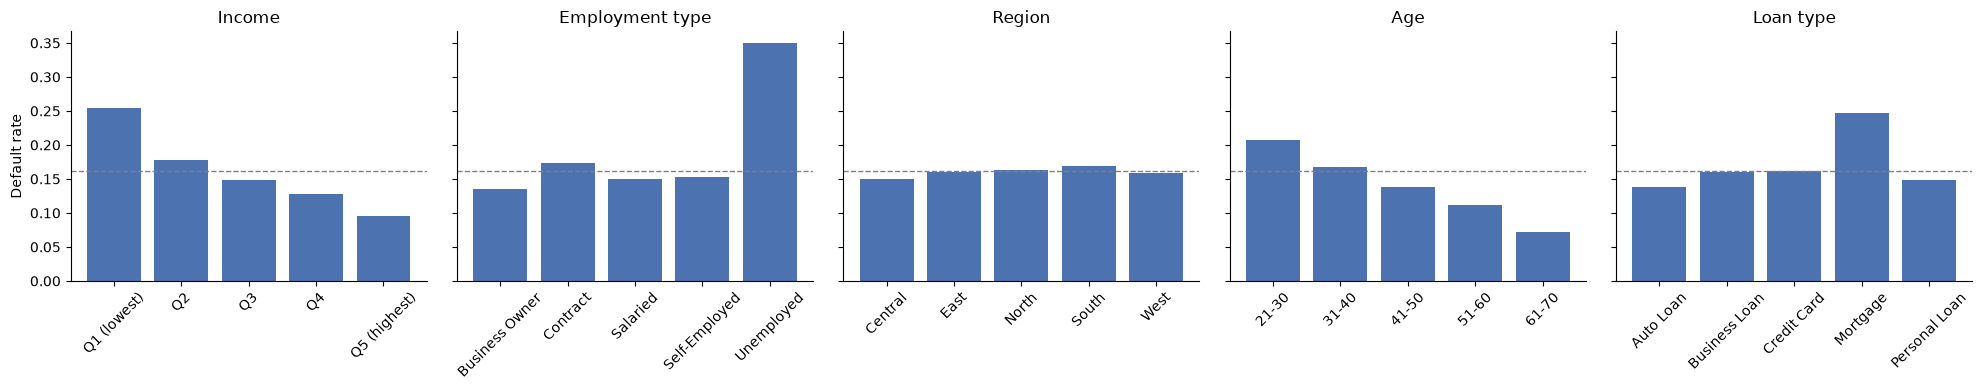

In [3]:
profiles = {}
for label, col in PROFILE_DIMENSIONS.items():
    s = segment_summary(df, col)
    profiles[label] = s
    s.to_csv(OUT / f"profile_{col}.csv")

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (label, s) in zip(axes, profiles.items()):
    s = s.sort_index()
    ax.bar(s.index.astype(str), s['default_rate'], color='#4C72B0')
    ax.axhline(df.target_default.mean(), ls='--', c='grey', lw=1)
    ax.set_title(label)
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Default rate')
plt.tight_layout()
plt.show()

In [4]:
profiles['Income'][['accounts', 'default_rate', 'risk_lift', 'exposure_share', 'avg_loan_amount']]

,accounts,default_rate,risk_lift,exposure_share,avg_loan_amount
income_band,,,,,
Q1 (lowest),2938,0.255,1.584,0.204,"41,460.803"
Q2,2980,0.177,1.101,0.206,"41,458.349"
Q3,2943,0.149,0.925,0.197,"40,232.485"
Q4,2919,0.128,0.794,0.201,"41,393.587"
Q5 (highest),2905,0.095,0.590,0.193,"40,113.504"


In [5]:
profiles['Employment type'][['accounts', 'default_rate', 'risk_lift', 'exposure_share', 'avg_loan_amount']]

,accounts,default_rate,risk_lift,exposure_share,avg_loan_amount
employment_type,,,,,
Unemployed,718,0.350,2.172,0.050,"41,261.173"
Contract,1563,0.173,1.077,0.102,"39,406.380"
Self-Employed,3014,0.153,0.952,0.205,"40,933.390"
Salaried,7546,0.150,0.930,0.521,"41,481.228"
Business Owner,1844,0.136,0.842,0.122,"39,865.103"


In [6]:
profiles['Region'][['accounts', 'default_rate', 'risk_lift', 'exposure_share', 'avg_loan_amount']]

,accounts,default_rate,risk_lift,exposure_share,avg_loan_amount
region,,,,,
South,3600,0.169,1.047,0.261,"43,407.732"
North,3147,0.164,1.017,0.215,"41,128.763"
East,2747,0.160,0.995,0.180,"39,390.688"
West,2877,0.158,0.982,0.183,"38,547.738"
Central,2314,0.150,0.932,0.161,"41,621.183"


In [7]:
profiles['Age'][['accounts', 'default_rate', 'risk_lift', 'exposure_share', 'avg_loan_amount']]

,accounts,default_rate,risk_lift,exposure_share,avg_loan_amount
age_band,,,,,
21-30,3648,0.208,1.289,0.265,"43,372.327"
31-40,5053,0.167,1.038,0.337,"40,200.058"
41-50,4113,0.138,0.855,0.275,"40,273.165"
51-60,1593,0.111,0.690,0.102,"38,516.600"
61-70,278,0.072,0.447,0.021,"45,920.570"


In [8]:
profiles['Loan type'][['accounts', 'default_rate', 'risk_lift', 'exposure_share', 'avg_loan_amount']]

,accounts,default_rate,risk_lift,exposure_share,avg_loan_amount
loan_type,,,,,
Mortgage,1432,0.247,1.531,0.582,"219,604.575"
Credit Card,3721,0.162,1.007,0.035,"8,066.875"
Business Loan,1484,0.160,0.996,0.152,"66,723.471"
Personal Loan,5216,0.149,0.925,0.102,"15,110.332"
Auto Loan,2832,0.139,0.862,0.129,"27,823.381"


### Exposure vs default rate by loan type
Risk isn't only about the rate. A segment with an average rate can still hold most of the money.

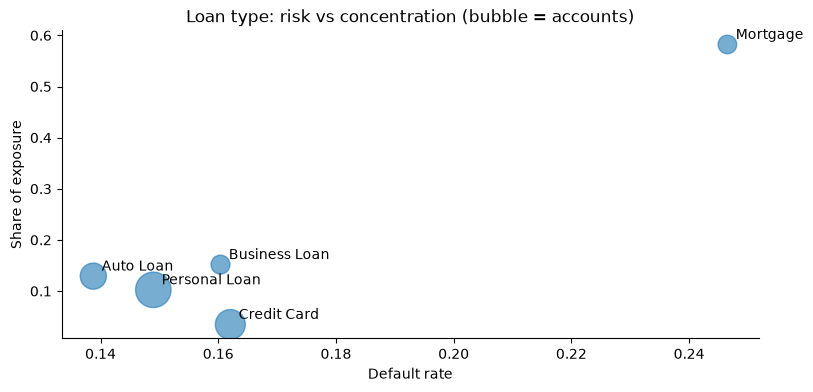

In [9]:
s = profiles['Loan type']
fig, ax = plt.subplots()
ax.scatter(s['default_rate'], s['exposure_share'], s=s['accounts'] / 8, alpha=.6)
for name, r in s.iterrows():
    ax.annotate(name, (r['default_rate'], r['exposure_share']), xytext=(6, 4), textcoords='offset points')
ax.set_xlabel('Default rate'); ax.set_ylabel('Share of exposure'); ax.set_title('Loan type: risk vs concentration (bubble = accounts)')
plt.show()

## 3. Cross-dimensional cuts

### Employment type × income band (default rate)

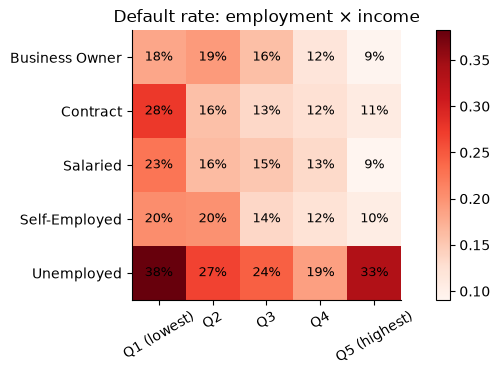

income_band,Q1 (lowest),Q2,Q3,Q4,Q5 (highest)
employment_type,,,,,
Business Owner,0.182,0.192,0.160,0.117,0.092
Contract,0.275,0.158,0.134,0.124,0.107
Salaried,0.226,0.163,0.152,0.133,0.091
Self-Employed,0.204,0.200,0.135,0.122,0.104
Unemployed,0.382,0.266,0.244,0.188,0.333


In [10]:
ct = cross_tab(df, 'employment_type', 'income_band')
ct.to_csv(OUT / 'crosstab_employment_x_income.csv')
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(ct.values, cmap='Reds')
ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=30)
ax.set_yticks(range(ct.shape[0]), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f'{ct.iat[i, j]:.0%}', ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax)
ax.set_title('Default rate: employment × income')
plt.show()
ct

In [11]:
segment_summary(df, ['employment_type', 'income_band'], min_accounts=100)[['accounts', 'default_rate', 'risk_lift']].head(8)

accounts  default_rate  risk_lift
employment_type income_band                                   
Unemployed      Q1 (lowest)       534         0.382      2.373
Contract        Q1 (lowest)       429         0.275      1.709
Unemployed      Q2                124         0.266      1.653
Salaried        Q1 (lowest)      1248         0.226      1.404
Self-Employed   Q1 (lowest)       573         0.204      1.268
                Q2                624         0.200      1.244
Business Owner  Q2                302         0.192      1.193
                Q1 (lowest)       154         0.182      1.129

### Region × loan type and loan type × prior bureau write-off

In [12]:
cross_tab(df, 'region', 'loan_type')

loan_type,Auto Loan,Business Loan,Credit Card,Mortgage,Personal Loan
region,,,,,
Central,0.118,0.191,0.153,0.213,0.133
East,0.154,0.160,0.178,0.223,0.136
North,0.148,0.149,0.161,0.253,0.154
South,0.150,0.153,0.155,0.273,0.162
West,0.116,0.156,0.165,0.255,0.152


In [13]:
cross_tab(df, 'loan_type', 'bureau_has_writeoff').rename(columns={0: 'no write-off', 1: 'has write-off'})

bureau_has_writeoff,no write-off,has write-off
loan_type,,
Auto Loan,0.132,0.154
Business Loan,0.144,0.202
Credit Card,0.150,0.192
Mortgage,0.234,0.275
Personal Loan,0.139,0.173


## 4. Behavioural and affordability signals

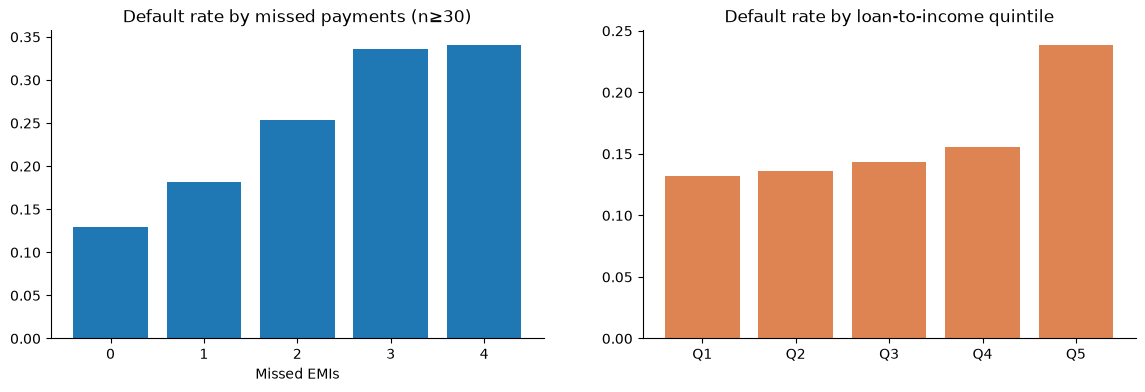

accounts  default_rate
missed EMIs    0       8573         0.129
               1       4456         0.181
               2       1287         0.253
               3        313         0.335
               4         47         0.340
loan-to-income Q1      2937         0.132
               Q2      2937         0.136
               Q3      2937         0.143
               Q4      2937         0.156
               Q5      2937         0.238

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
m = default_rate_by(df, 'rep_missed_cnt')
m = m[m.accounts >= 30]
axes[0].bar(m.index.astype(str), m['default_rate']); axes[0].set_title('Default rate by missed payments (n≥30)'); axes[0].set_xlabel('Missed EMIs')
l = default_rate_by(df, 'loan_to_income')
axes[1].bar(l.index.astype(str), l['default_rate'], color='#DD8452'); axes[1].set_title('Default rate by loan-to-income quintile')
plt.show()
pd.concat({'missed EMIs': m, 'loan-to-income': l})

In [15]:
df.groupby('orig_year')['target_default'].agg(accounts='size', default_rate='mean')  # vintage trend

,accounts,default_rate
orig_year,,
2018,2487,0.166
2019,2434,0.157
2020,2396,0.149
2021,2447,0.177
2022,2451,0.166
2023,2470,0.151


## 5. Key insights

| # | Insight | So what |
|---|---|---|
| 1 | **Mortgages are 9.8% of accounts but ~58% of exposure, and default at 24.7% (1.5× the portfolio).** Concentration risk and default risk land in the same segment. | Mortgage is where the loss is. Prioritise it for collateral revaluation, LTV review and tighter limits. Don't size risk appetite on the rate alone. |
| 2 | **Income is the clearest single gradient:** 25.5% default in the lowest income quintile vs 9.5% in the highest (2.7×). Age shows the same pattern (21–30: 20.8%, 61–70: 7.2%). | Build affordability into pricing and cut-offs. Thin-income young applicants need lower limits or a guarantor rather than an outright decline. |
| 3 | **Cross-cut: employment type matters mostly at low income.** Contract workers default at 27.5% in Q1 income but only 10.7% in Q5. Salaried Q1 is 22.6%, worse than Contract Q3–Q5. Unemployed Q1 is the riskiest pocket at 38.2% (2.4× lift). | A flat penalty by employment type is too blunt. Use employment × income segments in the scorecard and in limit-setting policy. |
| 4 | **Missed payments are an early-warning signal.** Default rises from 12.9% (0 missed) to 18.1% (1), 25.3% (2) and 33.5% (3). | Trigger proactive outreach (restructure offers, reminders) after the **first** missed EMI, before the account rolls into collections. |
| 5 | **Loan-to-income has a threshold, not a slope:** quintiles 1–4 sit at 13–16%, while the top quintile jumps to 23.8%. Region by contrast is nearly flat (15.0–16.9%). | Set a hard LTI cap or require extra review at the top quintile. Region is not a meaningful risk driver here, so don't build regional pricing on it. |
